
# CB5313 – Systems Biology & Network Modeling
## Directed Gene Regulatory Network Inference using GENIE3


**Dataset:** BEELINE mouse embryonic stem cell (mESC) single-cell RNA-seq

### Aim

The aim of this project is to use GENIE3 to infer directed gene regulatory networks from real single-cell gene expression data, and to study how the Random Forest parameter K affects the inferred network.

GENIE3 was introduced by Huynh-Thu et al. (2010). It uses tree-based regression to identify genes that are useful for predicting the expression of other genes. These relationships are then ranked as possible regulatory interactions.

The original paper showed strong performance on simulated DREAM4 networks, but also reported limitations when working with real biological data. For this project, I used mouse embryonic stem cell data from the BEELINE benchmark to examine how GENIE3 performs on single-cell expression measurements.

### Approach

1. Load the mESC expression data and select 100 transcription factors (TFs) and 400 other genes.
2. Run GENIE3 using different values of K: 1, 3, 9, 25, 50 and 99.
3. Compare predicted edges with ChIP-seq reference interactions using AUPR, AUROC and early precision.
4. Examine changes in feature importance, direction accuracy and network structure.
5. Compare results with and without the known TF list.
6. Test whether reducing the number of cells changes performance.
7. Compare GENIE3 with a simple correlation-based network.
8. Evaluate the predicted networks against a second reference, STRING.



**Research question:** *How do the Random Forest parameter K and prior transcription-factor (TF) knowledge affect the accuracy and structure of gene regulatory networks inferred by GENIE3 from real single-cell RNA-seq data?*

| | |
|---|---|
| **Primary paper** | Huynh-Thu VA, Irrthum A, Wehenkel L, Geurts P (2010). *Inferring Regulatory Networks from Expression Data Using Tree-Based Methods.* PLoS ONE 5(9): e12776. |
| **Method reference** | Original GENIE3 Python implementation — https://github.com/vahuynh/GENIE3 (`GENIE3_python/GENIE3.py`) |
| **Data** | **Mouse embryonic stem cells (mESC)**, single-cell RNA-seq of 421 cells sampled at 0, 12, 24, 48 and 72 h of differentiation (Hayashi et al. 2018, GEO GSE98664), as processed by the **BEELINE** benchmark (Pratapa et al. 2020, *Nature Methods*). |
| **Ground truth** | BEELINE's **cell-type-specific ChIP-seq network for mESC** (TF → target edges from ChIP-seq binding), plus the mouse **STRING** network as a second reference. |
| **Why this dataset** | It is *real* data (the paper's benchmark, DREAM4, is simulated) and *single-cell* (GENIE3 was designed for bulk data), and it differs from the package tutorial data (`data.txt`, 10 genes). It lets us test GENIE3's assumptions where they are most likely to fail. |


### Outline
1. Setup & configuration · 2. Download data · 3. Preprocessing (BEELINE procedure) · 4. Ground truth & evaluation design · 5. GENIE3 (adapted) · 6. Sanity checks · 7. Change 1: K sweep · 8. Structure vs K · 9. Error types · 10. Change 2: TF list on/off · 11. Change 3: number of cells · 12. Change 4: correlation baseline · 12b. ChIP-seq vs STRING · 13. Summary & saved outputs · 14. Interpretation · 15. Limitations & references

## 1. Setup and configuration

In [1]:
import os, sys, time, json, itertools, hashlib, zipfile, shutil, urllib.request
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import average_precision_score, roc_auc_score

for name, mod in [("python", sys), ("numpy", np), ("pandas", pd), ("scikit-learn", sklearn),
                  ("scipy", scipy), ("matplotlib", matplotlib)]:
    print(f"{name:13s}", sys.version.split()[0] if mod is sys else mod.__version__)
print("CPU cores    ", os.cpu_count())

python        3.13.18
numpy         2.4.6
pandas        2.2.3
scikit-learn  1.6.1
scipy         1.16.3
matplotlib    3.10.0
CPU cores     2


In [2]:
# ============================ CONFIGURATION ============================
# --- gene set (Section 3) ---
N_TFS   = 100     # most variable TFs kept as candidate regulators
N_GENES = 400     # most variable non-TF genes kept as additional targets
# BEELINE's standard "TFs+500" setting would be N_TFS = all significant TFs (620 for mESC),
# N_GENES = 500 -> ~1120 genes; that is ~10x slower, too slow for free Colab (see README).

# --- GENIE3 ---
K_VALUES = [1, 3, 'sqrt', 25, 50, 'all']   # 'sqrt' -> 10 and 'all' -> 100 with 100 TFs
NTREES   = int(os.environ.get("GENIE3_NTREES", 300))   # paper used 1000; checked in Section 6
SEED     = 0
N_JOBS   = -1

# --- Change 2: TF list off (all genes are candidate regulators) ---
K_NO_TF  = ['sqrt', 25]      # K = all with 499 inputs would take > 1 h, so it is skipped

# --- Change 3: number of cells ---
CELL_FRACTIONS = [0.25, 0.5]   # 1.0 is the main run
CELL_REPEATS   = 2             # random subsamples per fraction
K_CELLS        = 'sqrt'

USE_DRIVE = False              # True = cache in Google Drive (survives disconnects)
# ======================================================================
IN_COLAB = "google.colab" in sys.modules
if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/genie3_beeline_mESC"
else:
    BASE_DIR = os.path.abspath("genie3_beeline_mESC")
DATA_DIR    = os.path.join(BASE_DIR, "data")
CACHE_DIR   = os.path.join(BASE_DIR, "cache", f"tf{N_TFS}_g{N_GENES}_nt{NTREES}")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
for d in (DATA_DIR, CACHE_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)
print("Working directory:", BASE_DIR, "| trees:", NTREES)

Working directory: /content/genie3_beeline_mESC | trees: 300


In [3]:
# One consistent, colour-blind-safe plot style
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#9a9a94"
INK, INK2 = "#1f1f1e", "#5f5e58"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b8b7ae", "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False,
})

## 2. Download the data

Both archives come from the official BEELINE record on Zenodo (doi:10.5281/zenodo.3701939, version 3, licence CC BY-NC 4.0):

* `BEELINE-data.zip` (262 MB) — processed scRNA-seq inputs; we extract only `scRNA-Seq/mESC/`.
* `BEELINE-Networks.zip` (17 MB) — ground-truth networks and TF lists; we extract the mESC ChIP-seq network, the mouse TF list and (if present) the mouse STRING network, used as a second ground truth in Section 12b.

The cell writes a stand-alone `download_data.py` for the GitHub repository (raw data is not committed) and runs it. MD5 checksums are verified against the values published on Zenodo.

In [4]:
%%writefile download_data.py
"""Download the BEELINE mESC scRNA-seq data and ground truth from Zenodo (record 3701939, v3).

Usage:  python download_data.py [output_dir]      (default: ./data)
Extracts: ExpressionData.csv, GeneOrdering.csv, PseudoTime.csv (mESC),
          mESC-ChIP-seq-network.csv, mouse-tfs.csv
"""
import hashlib, os, shutil, sys, urllib.request, zipfile

ZENODO = "https://zenodo.org/records/3701939/files/{}?download=1"
ARCHIVES = {   # name: published md5
    "BEELINE-data.zip":     "52581e7e27aa699310384238daac4751",
    "BEELINE-Networks.zip": "a7dca84d302bb127bad962ae52815662",
}
WANTED = {     # file name inside the archive -> must appear in this path fragment
    "ExpressionData.csv":        "scRNA-Seq/mESC/",
    "GeneOrdering.csv":          "scRNA-Seq/mESC/",
    "PseudoTime.csv":            "scRNA-Seq/mESC/",
    "mESC-ChIP-seq-network.csv": "Networks/mouse/",
    "mouse-tfs.csv":             "",
}
OPTIONAL = {   # extracted if present (second ground truth); skipped otherwise
    "STRING-network.csv":        "mouse",
}

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def main(out_dir="data"):
    os.makedirs(out_dir, exist_ok=True)
    local = os.environ.get("BEELINE_LOCAL_DIR")      # optional: use already-downloaded zips
    for name, checksum in ARCHIVES.items():
        zpath = os.path.join(out_dir, name)
        if not os.path.exists(zpath):
            if local:
                shutil.copy(os.path.join(local, name), zpath)
            else:
                print(f"downloading {name} ...", flush=True)
                urllib.request.urlretrieve(ZENODO.format(name), zpath)
            if not local and md5(zpath) != checksum:
                os.remove(zpath)
                raise RuntimeError(f"MD5 mismatch for {name}; download again")
        with zipfile.ZipFile(zpath) as z:
            for member in z.namelist():
                base = os.path.basename(member)
                frag = WANTED.get(base, OPTIONAL.get(base))
                if frag is not None and frag in member and "__MACOSX" not in member:
                    target = os.path.join(out_dir, base)
                    if not os.path.exists(target):
                        with z.open(member) as src, open(target, "wb") as dst:
                            shutil.copyfileobj(src, dst)
                    print("extracted", member)
    missing = [f for f in WANTED if not os.path.exists(os.path.join(out_dir, f))]
    if missing:
        raise RuntimeError(f"not found in the archives: {missing}")
    for f in OPTIONAL:
        print(f"optional {f}:", "found" if os.path.exists(os.path.join(out_dir, f)) else "not found (skipped)")
    print("all required files present in", out_dir)

if __name__ == "__main__":
    main(sys.argv[1] if len(sys.argv) > 1 else "data")

Writing download_data.py


In [5]:
!python download_data.py "{DATA_DIR}"

downloading BEELINE-data.zip ...
extracted BEELINE-data/inputs/scRNA-Seq/mESC/PseudoTime.csv
extracted BEELINE-data/inputs/scRNA-Seq/mESC/ExpressionData.csv
extracted BEELINE-data/inputs/scRNA-Seq/mESC/GeneOrdering.csv
downloading BEELINE-Networks.zip ...
extracted Networks/mouse/STRING-network.csv
extracted Networks/mouse/mESC-ChIP-seq-network.csv
extracted mouse-tfs.csv
optional STRING-network.csv: found
all required files present in /content/genie3_beeline_mESC/data


## 3. Preprocessing — the BEELINE procedure, scaled down

BEELINE's `generateExpInputs.py` selects genes as follows, and follow it step by step:

1. Keep genes whose expression varies significantly over pseudotime: `VGAMpValue` < 0.01, **Bonferroni-corrected** (divided by the number of genes).
2. Among them, keep the TFs (from BEELINE's mouse TF list) and the most variable non-TF genes.

**The one change:** BEELINE keeps *all* significant TFs (620 for mESC) + 500 genes. With 620 candidate regulators, GENIE3 at K = all takes over an hour per run on a free Colab CPU, which makes a K sweep impossible. We therefore keep the **100 most variable significant TFs + 400 most variable non-TF genes** (500 genes), choosing by variance exactly as BEELINE chooses genes. `N_TFS` and `N_GENES` in the config cell restore the full setting.

**Gene names.** The ChIP-seq network and TF list use upper-case symbols (e.g. `ADNP`), the expression file uses mouse-style symbols (e.g. `Sparc`). All names are converted to upper case before matching — without this, almost no TF would be matched.

`ExpressionData.csv` is genes × cells and already log-transformed by BEELINE; it is transposed to cells × genes for GENIE3.

In [6]:
def upper_unique(index):
    return pd.Index(index).astype(str).str.upper()

# ---- expression: genes x cells -> cells x genes
expr_raw = pd.read_csv(os.path.join(DATA_DIR, "ExpressionData.csv"), index_col=0)
expr_raw.index = upper_unique(expr_raw.index)
expr_raw = expr_raw[~expr_raw.index.duplicated(keep="first")]
print("Expression data:", expr_raw.shape[0], "genes x", expr_raw.shape[1], "cells")

# ---- gene ordering (p-value, variance) and TF list
order = pd.read_csv(os.path.join(DATA_DIR, "GeneOrdering.csv"), index_col=0)
order.index = upper_unique(order.index)
order = order[~order.index.duplicated(keep="first")]
order = order[order.index.isin(expr_raw.index)]
pcol, vcol = order.columns[0], order.columns[1]
tf_list = set(upper_unique(pd.read_csv(os.path.join(DATA_DIR, "mouse-tfs.csv")).iloc[:, 0]))

# ---- step 1: Bonferroni-corrected significance over pseudotime
cutoff = 0.01 / len(order)
sig = order[order[pcol] < cutoff]
print(f"{len(sig)} / {len(order)} genes significant (p < {cutoff:.2e})")

# ---- step 2: most variable TFs + most variable non-TF genes
sig_tfs  = sig[sig.index.isin(tf_list)].sort_values(vcol, ascending=False)
sig_rest = sig[~sig.index.isin(tf_list)].sort_values(vcol, ascending=False)
print(f"{len(sig_tfs)} significant TFs available; keeping {min(N_TFS, len(sig_tfs))}")
TFS   = list(sig_tfs.index[:N_TFS])
GENES = sorted(set(TFS) | set(sig_rest.index[:N_GENES]))
TF_IDX = [GENES.index(t) for t in TFS]               # column indices of the TFs
P = len(GENES)

EXPR_ALL = expr_raw.loc[GENES].T.values.astype(float)   # cells x genes
CELLS = list(expr_raw.columns)
print(f"Final matrix: {EXPR_ALL.shape[0]} cells x {P} genes ({len(TFS)} TFs)")
print(f"Fraction of zero values (dropout): {(EXPR_ALL == 0).mean():.1%}")

Expression data: 18385 genes x 421 cells
8150 / 18385 genes significant (p < 5.44e-07)
620 significant TFs available; keeping 100
Final matrix: 421 cells x 500 genes (100 TFs)
Fraction of zero values (dropout): 12.9%


cells per time point: {'00h': 90, '12h': 68, '24h': 90, '48h': 82, '72h': 91}


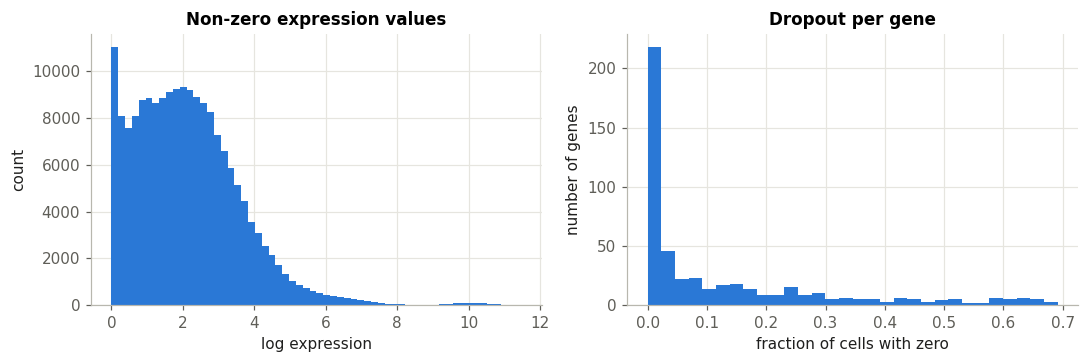

In [7]:
# Cells come from 5 time points of differentiation -> the samples are NOT independent
# steady states (a GENIE3 assumption). The time point is encoded in the cell name.
tp = pd.Series(CELLS).str.extract(r"_(\d+h)_")[0]
print("cells per time point:", tp.value_counts().sort_index().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(EXPR_ALL[EXPR_ALL > 0].ravel(), bins=60, color=BLUE)
axes[0].set(title="Non-zero expression values", xlabel="log expression", ylabel="count")
axes[1].hist((EXPR_ALL == 0).mean(axis=0), bins=30, color=BLUE)
axes[1].set(title="Dropout per gene", xlabel="fraction of cells with zero", ylabel="number of genes")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig0_data_overview.png")); plt.show()

## 4. Ground truth and evaluation design

The mESC ChIP-seq network lists TF → target edges supported by ChIP-seq binding. Two facts shape the evaluation:

* **Only some TFs were profiled by ChIP-seq.** For a TF without ChIP data, we do not know which of its edges are real — counting them all as false would be wrong. **Edges are therefore scored only for regulators that have ChIP-seq data** ("evaluable TFs"), against all possible targets.
* **ChIP-seq binding ≠ regulation**, and binding sites are incomplete, so the ground truth itself is noisy. Absolute scores are expected to be low; the comparison *between settings* is what matters.

Metrics (as in BEELINE):

* **AUPR** and **AUPR ratio** = AUPR / edge density (= AUPR of a random predictor). A ratio of 1 means random.
* **EPR** (early precision ratio) = precision of the top-*k* scored edges / edge density, with *k* = number of true edges.
* **AUROC** (random = 0.5).

> **Note on density.** The mESC ChIP-seq network is dense: a large fraction of all TF → gene pairs of the profiled TFs count as "true". A random predictor therefore already has a high AUPR, and the *maximum* possible AUPR ratio is only 1 / density (printed below). Compare AUPR ratios with that ceiling, not with DREAM4 values (where density was ~2%).

In [8]:
gidx = {g: k for k, g in enumerate(GENES)}

def make_truth(path):
    '''Load a BEELINE network (Gene1 -> Gene2), restrict it to our genes and build:
    the gold matrix (rows = regulators, columns = targets), the mask of scored edges
    (rows = TFs with at least one edge in this network), number of true edges, density.'''
    net = pd.read_csv(path).iloc[:, :2]
    net.columns = ["Gene1", "Gene2"]
    net["Gene1"], net["Gene2"] = upper_unique(net.Gene1), upper_unique(net.Gene2)
    net = net[net.Gene1.isin(GENES) & net.Gene2.isin(GENES) & (net.Gene1 != net.Gene2)].drop_duplicates()
    gold = np.zeros((P, P), dtype=int)
    gold[net.Gene1.map(gidx).values, net.Gene2.map(gidx).values] = 1
    regs = sorted({gidx[g] for g in net.Gene1.unique()} & set(TF_IDX))      # evaluable TFs
    mask = np.zeros((P, P), dtype=bool); mask[regs, :] = True; np.fill_diagonal(mask, False)
    n_true = int(gold[mask].sum())
    return {"net": net, "GOLD": gold, "EVAL_REGS": regs, "EVAL_MASK": mask,
            "N_TRUE": n_true, "DENSITY": n_true / mask.sum()}

CHIP = make_truth(os.path.join(DATA_DIR, "mESC-ChIP-seq-network.csv"))
net, GOLD, EVAL_REGS, EVAL_MASK, N_TRUE, DENSITY = (CHIP[k] for k in
                                                     ["net", "GOLD", "EVAL_REGS", "EVAL_MASK", "N_TRUE", "DENSITY"])

print(f"Ground-truth edges within the gene set: {len(net)}")
print(f"Evaluable TFs (with ChIP-seq data): {len(EVAL_REGS)} of {len(TFS)} TFs: "
      + ", ".join(GENES[i] for i in EVAL_REGS))
print(f"Scored edges: {EVAL_MASK.sum()}, true: {N_TRUE}, density (random AUPR): {DENSITY:.4f}")
print(f"Best possible AUPR ratio for this ground truth: 1 / density = {1 / DENSITY:.1f}")
outdeg = pd.Series(GOLD[EVAL_REGS].sum(1), index=[GENES[i] for i in EVAL_REGS]).sort_values(ascending=False)
print("Largest ChIP-seq hubs:", outdeg.head(8).to_dict())

Ground-truth edges within the gene set: 4853
Evaluable TFs (with ChIP-seq data): 27 of 100 TFs: CBX7, EED, ESRRB, GATA4, JARID2, KDM5B, KLF2, KLF4, MTF2, MYC, MYCN, NANOG, NFYA, NR0B1, NRF1, PARP1, PHC1, POU5F1, SOX17, SOX2, SUZ12, TBX3, TGIF1, TRIM28, UTF1, ZFP42, ZIC3
Scored edges: 13473, true: 4046, density (random AUPR): 0.3003
Best possible AUPR ratio for this ground truth: 1 / density = 3.3
Largest ChIP-seq hubs: {'NANOG': 352, 'UTF1': 339, 'POU5F1': 326, 'NRF1': 323, 'SUZ12': 271, 'KLF4': 270, 'ESRRB': 257, 'SOX2': 227}


## 5. GENIE3 — adapted from the original implementation

For each target gene, GENIE3 scales its expression to unit variance, trains a Random Forest predicting it from the candidate regulators, and uses each regulator's **variance-reduction importance** as the weight of the edge *regulator → target*. `VIM[i, j]` = score of edge *gene i → gene j* (rows = regulators, columns = targets).

**K** = `max_features`: how many randomly drawn candidate regulators each split may choose from.

| Original code | This notebook | Reason |
|---|---|---|
| `max_features = "auto"` when K = 'all' | `max_features = None` | `"auto"` was removed in scikit-learn 1.3; `None` = all features, identical behaviour |
| no `random_state` | `random_state` set per target | reproducibility |
| `multiprocessing.Pool` | `n_jobs=-1` inside each forest | `Pool` is unreliable in notebooks; same result |
| — | target genes with zero variance are skipped | a gene that is zero in every cell (possible after subsampling cells) cannot be normalised |

The importance computation (`compute_feature_importances(normalize=False)`, averaged over trees) and the output normalisation are unchanged. The `regulators` argument is the original's TF list option.

In [9]:
def compute_feature_importances(forest):
    '''Unnormalised variance-reduction importances averaged over trees (as in the original).'''
    return np.mean([t.tree_.compute_feature_importances(normalize=False) for t in forest.estimators_], axis=0)


def genie3_single(expr, target_idx, input_idx, K, ntrees, seed):
    '''One forest predicting gene `target_idx` from `input_idx` (minus itself).
    Returns a length-p vector of edge scores input -> target.'''
    n_genes = expr.shape[1]
    vi = np.zeros(n_genes)
    sd = np.std(expr[:, target_idx])
    if sd == 0:                       # ADAPTED: constant gene -> nothing to learn
        return vi
    y = expr[:, target_idx] / sd      # unit-variance output, as in the original
    inputs = [i for i in input_idx if i != target_idx]
    if K == 'all' or (isinstance(K, int) and K >= len(inputs)):
        max_features = None           # ADAPTED: original "auto"
    else:
        max_features = K
    forest = RandomForestRegressor(n_estimators=ntrees, max_features=max_features,
                                   random_state=seed * 100_000 + target_idx, n_jobs=N_JOBS)
    forest.fit(expr[:, inputs], y)
    vi[inputs] = compute_feature_importances(forest)
    return vi


def genie3(expr, K='sqrt', ntrees=1000, seed=0, regulators=None):
    '''Full GENIE3 (one forest per target). `regulators`: list of column indices allowed as
    regulators (the TF list); None = all genes. Returns VIM (rows = regulators, cols = targets).'''
    n_genes = expr.shape[1]
    input_idx = list(range(n_genes)) if regulators is None else list(regulators)
    VIM = np.zeros((n_genes, n_genes))
    for j in range(n_genes):
        VIM[:, j] = genie3_single(expr, j, input_idx, K, ntrees, seed)
    return VIM


def effective_K(K, n_inputs):
    if K == 'all':  return n_inputs
    if K == 'sqrt': return max(1, int(np.sqrt(n_inputs)))
    return min(int(K), n_inputs)

N_IN_TF = len(TFS) - 1          # inputs for a TF target (a TF target cannot regulate itself)
K_LABEL = {K: (f"{effective_K(K, N_IN_TF)} (√)" if K == 'sqrt' else f"{effective_K(K, N_IN_TF)} (all)"
               if K == 'all' else str(K)) for K in K_VALUES}
print("effective K with the TF list:", {str(K): effective_K(K, len(TFS)) for K in K_VALUES})

effective K with the TF list: {'1': 1, '3': 3, 'sqrt': 10, '25': 25, '50': 50, 'all': 100}


In [10]:
def cache_path(tag):
    return os.path.join(CACHE_DIR, f"VIM_{tag}.npy")

def run_or_load(tag, expr, K, regulators, seed=SEED):
    '''Run GENIE3 or load it from the cache. Returns (VIM, seconds).'''
    path, tpath = cache_path(tag), cache_path(tag).replace(".npy", "_time.json")
    if os.path.exists(path):
        return np.load(path), json.load(open(tpath))["seconds"]
    t0 = time.time()
    VIM = genie3(expr, K=K, ntrees=NTREES, seed=seed, regulators=regulators)
    secs = time.time() - t0
    np.save(path, VIM); json.dump({"seconds": secs}, open(tpath, "w"))
    return VIM, secs

## 6.Checking the Implementation

1. **Eq. 4 of the paper:** a target's importances should sum to ≈ its variance (= 1 after normalisation). On noisy single-cell data the trees fit noise too, so the sum is still ≈ 1 — it does *not* mean the regulators are real.
2. **Number of trees:** rankings with `NTREES` vs 1000 trees on 5 targets.

In [11]:
vi = genie3_single(EXPR_ALL, TF_IDX[0], TF_IDX, 'sqrt', NTREES, SEED)
print(f"Check 1  sum of importances for target {GENES[TF_IDX[0]]} = {vi.sum():.3f}  (expected ≈ 1)")

rhos = []
targets = [j for j in range(P) if np.std(EXPR_ALL[:, j]) > 0][:5]
for j in targets:
    a = genie3_single(EXPR_ALL, j, TF_IDX, 'sqrt', NTREES, SEED)
    b = genie3_single(EXPR_ALL, j, TF_IDX, 'sqrt', 1000, SEED + 1)
    m = np.isin(np.arange(P), TF_IDX) & (np.arange(P) != j)
    rhos.append(spearmanr(a[m], b[m])[0])
print(f"Check 2  Spearman of TF importances, {NTREES} vs 1000 trees: mean {np.mean(rhos):.3f} (min {np.min(rhos):.3f})")

Check 1  sum of importances for target DAB2 = 0.998  (expected ≈ 1)
Check 2  Spearman of TF importances, 300 vs 1000 trees: mean 0.945 (min 0.931)


## 7. Change 1 — the K sweep (TF list on)

Main analysis: GENIE3 with the 100 TFs as candidate regulators (the setting the paper recommends for real data), for each K.

In [12]:
MAIN, RT = {}, {}
t_start = time.time()
for K in K_VALUES:
    MAIN[K], RT[K] = run_or_load(f"main_K{K}", EXPR_ALL, K, TF_IDX)
    print(f"K = {K_LABEL[K]:>9}  done ({RT[K]:6.1f} s)   elapsed {time.time() - t_start:6.0f} s")

K =         1  done ( 308.5 s)   elapsed    309 s
K =         3  done ( 383.1 s)   elapsed    692 s
K =     9 (√)  done ( 697.0 s)   elapsed   1389 s
K =        25  done (1370.0 s)   elapsed   2759 s
K =        50  done (2436.1 s)   elapsed   5195 s
K =  99 (all)  done (4576.9 s)   elapsed   9772 s


In [13]:
def scored(VIM, T=CHIP):
    return VIM[T["EVAL_MASK"]], T["GOLD"][T["EVAL_MASK"]]

def top_k_mask(VIM, k=None, T=CHIP):
    '''Boolean P x P matrix of the k highest-scoring *evaluable* edges (k = number of true edges).'''
    k = T["N_TRUE"] if k is None else k
    s = np.where(T["EVAL_MASK"], VIM, -np.inf).ravel()
    keep = np.argsort(-s, kind="stable")[:k]
    A = np.zeros(P * P, dtype=bool); A[keep] = True
    return A.reshape(P, P)

def accuracy_metrics(VIM, T=CHIP):
    '''AUPR, AUPR ratio, EPR and AUROC of a score matrix against ground truth T (default ChIP-seq).'''
    s, y = scored(VIM, T)
    aupr = average_precision_score(y, s)
    prec = (top_k_mask(VIM, T=T) & (T["GOLD"] == 1)).sum() / T["N_TRUE"]
    return {"AUPR": aupr, "AUPR ratio": aupr / T["DENSITY"], "EPR": prec / T["DENSITY"],
            "AUROC": roc_auc_score(y, s)}

acc = pd.DataFrame([{"K": K_LABEL[K], "K_eff": effective_K(K, N_IN_TF), **accuracy_metrics(MAIN[K]),
                     "seconds": RT[K]} for K in K_VALUES]).set_index("K")
acc.round(4)

,K_eff,AUPR,AUPR ratio,EPR,AUROC,seconds
K,,,,,,
1,1,0.3076,1.0244,1.0708,0.4782,308.5319
3,3,0.3066,1.0211,1.0403,0.4699,383.1373
9 (√),9,0.2959,0.9854,0.9506,0.4431,697.0203
25,25,0.2859,0.9519,0.8518,0.4296,1370.0104
50,50,0.2779,0.9254,0.7810,0.4244,2436.1378
99 (all),99,0.2697,0.8980,0.7185,0.4176,4576.8759


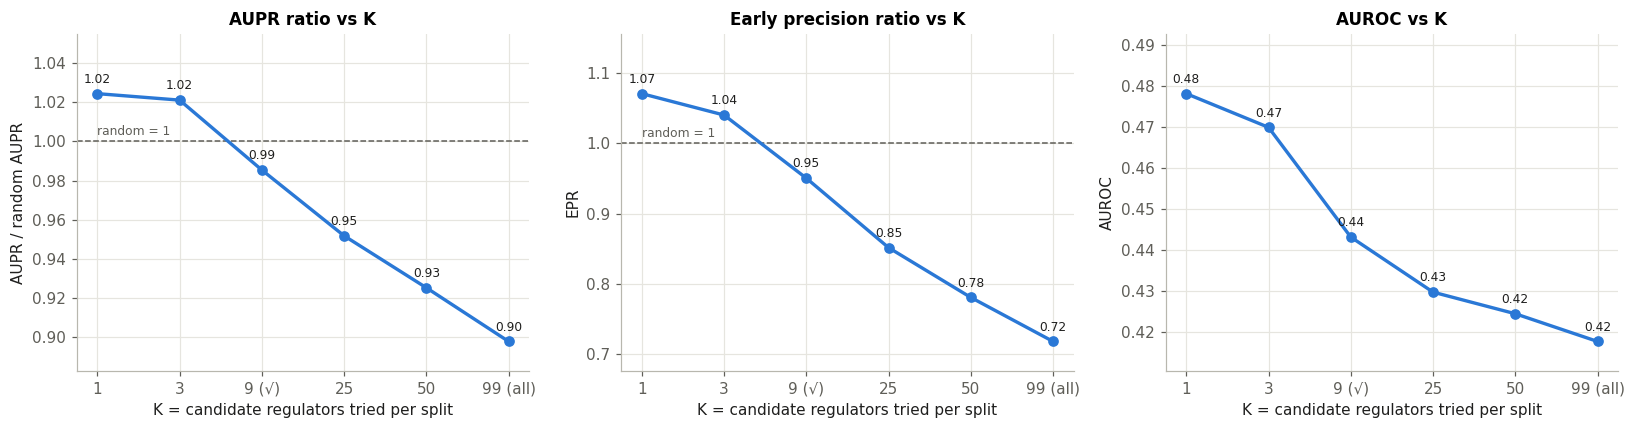

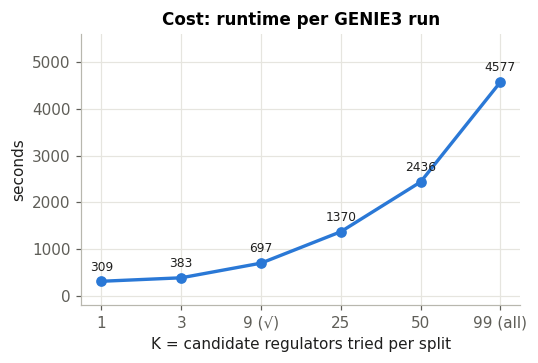

In [14]:
def line_plot(ax, x_labels, values, title, ylabel, baseline=None, baseline_label=None, fmt="{:.2f}", color=BLUE):
    x = np.arange(len(x_labels))
    ax.plot(x, values, color=color, lw=2.2, marker="o", ms=6, zorder=3)
    for xi, yi in zip(x, values):
        ax.annotate(fmt.format(yi), (xi, yi), xytext=(0, 7), textcoords="offset points",
                    ha="center", fontsize=8, color=INK)
    if baseline is not None:
        ax.axhline(baseline, color=INK2, lw=1, ls="--", zorder=1)
        ax.annotate(baseline_label, (x[0], baseline), xytext=(0, 4), textcoords="offset points",
                    fontsize=8, color=INK2)
    ax.set_xticks(x, x_labels)
    ax.set(title=title, xlabel="K = candidate regulators tried per split", ylabel=ylabel)
    lo, hi = min(list(values) + ([baseline] if baseline is not None else [])), max(values)
    pad = 0.12 * (hi - lo if hi > lo else 1)
    ax.set_ylim(lo - pad, hi + 2 * pad)

xl = list(acc.index)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
line_plot(axes[0], xl, acc["AUPR ratio"], "AUPR ratio vs K", "AUPR / random AUPR", 1, "random = 1")
line_plot(axes[1], xl, acc["EPR"], "Early precision ratio vs K", "EPR", 1, "random = 1")
line_plot(axes[2], xl, acc["AUROC"], "AUROC vs K", "AUROC", 0.5, "random = 0.5")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig1_accuracy_vs_K.png")); plt.show()

fig, ax = plt.subplots(figsize=(5, 3.4))
line_plot(ax, xl, acc["seconds"], "Cost: runtime per GENIE3 run", "seconds", fmt="{:.0f}")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig1b_runtime_vs_K.png")); plt.show()

In [15]:
# How far is each K from random? A permutation null for AUPR:
# shuffle the scores among the evaluable edges 200 times.
rng = np.random.default_rng(0)
s0, y0 = scored(MAIN['sqrt'])
null = np.array([average_precision_score(y0, rng.permutation(s0)) for _ in range(200)])
print(f"Random AUPR: mean {null.mean():.4f}, 99th percentile {np.percentile(null, 99):.4f}")
for K in K_VALUES:
    a = acc.loc[K_LABEL[K], "AUPR"]
    print(f"K = {K_LABEL[K]:>9}: AUPR {a:.4f}  ->  {'above' if a > np.percentile(null, 99) else 'NOT above'} the 99th percentile of random")

Random AUPR: mean 0.3007, 99th percentile 0.3094
K =         1: AUPR 0.3076  ->  NOT above the 99th percentile of random
K =         3: AUPR 0.3066  ->  NOT above the 99th percentile of random
K =     9 (√): AUPR 0.2959  ->  NOT above the 99th percentile of random
K =        25: AUPR 0.2859  ->  NOT above the 99th percentile of random
K =        50: AUPR 0.2779  ->  NOT above the 99th percentile of random
K =  99 (all): AUPR 0.2697  ->  NOT above the 99th percentile of random


## 8. Structure vs K

| Measure | What it captures |
|---|---|
| **Effective number of regulators per target** | 1/Σw² of each target's normalised importances: ~1 = one dominant regulator, ~100 = spread evenly over all TFs |
| **Direction accuracy (TF→TF edges)** | For true edges A→B between two evaluable TFs (B→A not true): fraction with score(A→B) > score(B→A). Random = 0.5 |
| **Hub recovery** | Spearman correlation between each evaluable TF's out-degree in the top-*k* network and in the ChIP-seq network |
| **Overlap between K values** | Jaccard index of the top-*k* edge sets |

In [16]:
EVAL_SET = set(EVAL_REGS)
tt_i, tt_j = np.where((GOLD == 1) & (GOLD.T == 0))
tt = [(i, j) for i, j in zip(tt_i, tt_j) if i in EVAL_SET and j in EVAL_SET]
print(f"TF->TF true edges usable for direction accuracy: {len(tt)}")

def structure_metrics(VIM):
    W = VIM[TF_IDX]                                      # TF rows only
    colsum = W.sum(axis=0)
    ok = colsum > 0
    Wn = W[:, ok] / colsum[ok]
    eff = np.mean(1.0 / (Wn ** 2).sum(axis=0))
    if tt:
        f = np.array([VIM[i, j] for i, j in tt]); r = np.array([VIM[j, i] for i, j in tt])
        dacc = np.mean((f > r) + 0.5 * (f == r))
    else:
        dacc = np.nan
    top = top_k_mask(VIM)
    hub = spearmanr(top[EVAL_REGS].sum(1), GOLD[EVAL_REGS].sum(1))[0]
    return {"effective regulators / target": eff, "direction accuracy (TF→TF)": dacc,
            "hub recovery (Spearman)": hub}

struct = pd.DataFrame([{"K": K_LABEL[K], **structure_metrics(MAIN[K])} for K in K_VALUES]).set_index("K")
struct.round(3)

TF->TF true edges usable for direction accuracy: 172


,effective regulators / target,direction accuracy (TF→TF),hub recovery (Spearman)
K,,,
1,89.455,0.401,-0.031
3,70.591,0.477,-0.085
9 (√),45.725,0.500,-0.061
25,30.387,0.483,-0.061
50,22.434,0.459,0.073
99 (all),17.253,0.453,0.173


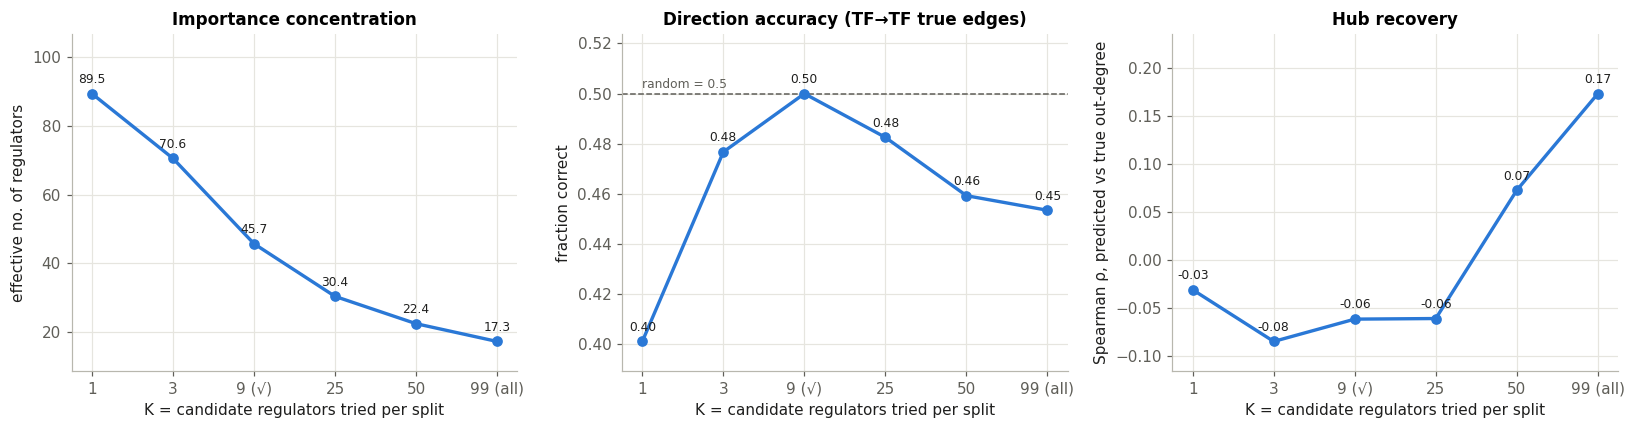

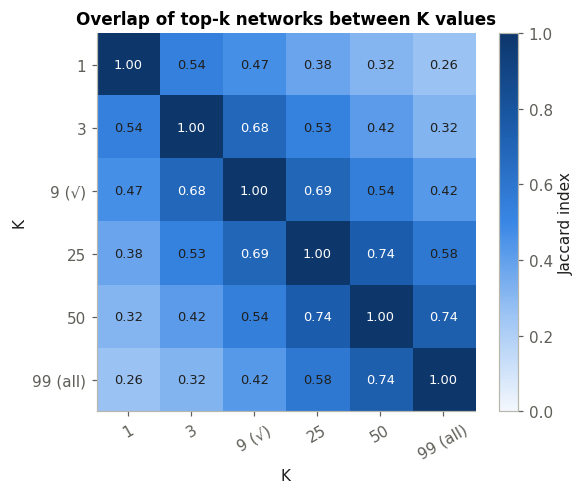

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
line_plot(axes[0], xl, struct.iloc[:, 0], "Importance concentration", "effective no. of regulators", fmt="{:.1f}")
line_plot(axes[1], xl, struct.iloc[:, 1], "Direction accuracy (TF→TF true edges)", "fraction correct", 0.5, "random = 0.5")
line_plot(axes[2], xl, struct.iloc[:, 2], "Hub recovery", "Spearman ρ, predicted vs true out-degree")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig2_structure_vs_K.png")); plt.show()

def jaccard(A, B):
    return (A & B).sum() / (A | B).sum()
tops = [top_k_mask(MAIN[K]) for K in K_VALUES]
J = np.array([[jaccard(a, b) for b in tops] for a in tops])

from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(J, cmap=blues, vmin=0, vmax=1)
ax.set_xticks(range(len(xl)), xl, rotation=30); ax.set_yticks(range(len(xl)), xl)
for a in range(len(xl)):
    for b in range(len(xl)):
        ax.text(b, a, f"{J[a, b]:.2f}", ha="center", va="center", fontsize=8.5, color="white" if J[a, b] > 0.6 else INK)
ax.grid(False); ax.set(title="Overlap of top-k networks between K values", xlabel="K", ylabel="K")
plt.colorbar(im, ax=ax, fraction=0.046, label="Jaccard index")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig3_overlap_between_K.png")); plt.show()

## 9. What kind of mistakes does each K make?

Each edge A→B in the top-*k* network (k = number of true edges) is classified, in this order:

1. **True positive** — A→B is in the ChIP-seq network.
2. **Reversed** — B→A is (only detectable when B is an evaluable TF).
3. **Indirect (A→C→B)** — A binds some C that binds B.
4. **Co-regulated (C→A and C→B)** — A and B share a regulator C, so they are correlated.
5. **Other** — no explanation from the ground truth (could be a true edge ChIP-seq missed, or noise).

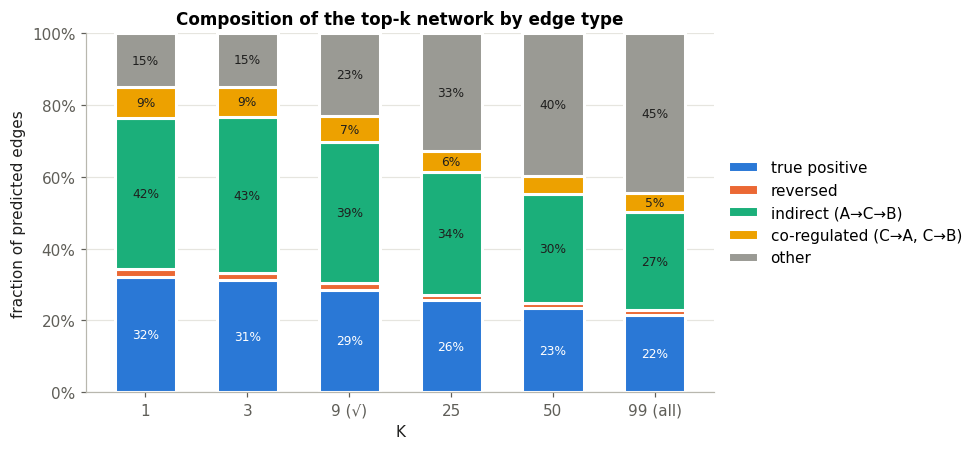

,true positive,reversed,indirect (A→C→B),"co-regulated (C→A, C→B)",other
K,,,,,
1,0.322,0.021,0.421,0.086,0.151
3,0.312,0.020,0.433,0.086,0.149
9 (√),0.285,0.019,0.391,0.073,0.231
25,0.256,0.015,0.343,0.057,0.328
50,0.235,0.015,0.304,0.050,0.397
99 (all),0.216,0.013,0.273,0.052,0.446


In [18]:
CATS = ["true positive", "reversed", "indirect (A→C→B)", "co-regulated (C→A, C→B)", "other"]
CAT_COLORS = [BLUE, ORANGE, AQUA, YELLOW, GREY]
TWO_STEP = (GOLD @ GOLD) > 0
CO_REG   = (GOLD.T @ GOLD) > 0

def classify_errors(VIM):
    counts = dict.fromkeys(CATS, 0)
    for i, j in zip(*np.where(top_k_mask(VIM))):
        if GOLD[i, j]:        counts["true positive"] += 1
        elif GOLD[j, i]:      counts["reversed"] += 1
        elif TWO_STEP[i, j]:  counts["indirect (A→C→B)"] += 1
        elif CO_REG[i, j]:    counts["co-regulated (C→A, C→B)"] += 1
        else:                 counts["other"] += 1
    return {c: v / N_TRUE for c, v in counts.items()}

def stacked_bars(ax, table, title):
    bottom = np.zeros(len(table))
    for c, col in zip(CATS, CAT_COLORS):
        vals = table[c].values
        ax.bar(table.index, vals, bottom=bottom, color=col, width=0.6, label=c, edgecolor="white", linewidth=2)
        for x, v, b in zip(table.index, vals, bottom):
            if v > 0.05:
                ax.text(x, b + v / 2, f"{v:.0%}", ha="center", va="center", fontsize=8,
                        color="white" if col == BLUE else INK)
        bottom += vals
    ax.set(title=title, ylabel="fraction of predicted edges", ylim=(0, 1))
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0)); ax.grid(axis="x", visible=False)
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))

err = pd.DataFrame([{"K": K_LABEL[K], **classify_errors(MAIN[K])} for K in K_VALUES]).set_index("K")
fig, ax = plt.subplots(figsize=(9, 4.2))
stacked_bars(ax, err, "Composition of the top-k network by edge type"); ax.set_xlabel("K")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig4_error_types_vs_K.png")); plt.show()
err.round(3)

## 10. Change 2 — TF list on vs off

The paper found that on real *E. coli* data, without a list of known TFs, precision never exceeded 6% (the limitation discussed in the synopsis). Here every gene (499 inputs) is allowed to regulate every other gene, at K = √ and K = 25, and compared with the TF-list runs.

Two views:

* **Scored edges only** (same evaluable TF → target edges as before): does competing with 400 extra non-TF genes change how the true TFs are ranked?
* **Whole network:** in the global top-*k* edges of the TF-off network, what fraction have a regulator that *is not a TF at all*? Those edges are biologically implausible as direct transcriptional regulation and would all be wrong.

In [19]:
NOTF, RT_NOTF = {}, {}
for K in K_NO_TF:
    NOTF[K], RT_NOTF[K] = run_or_load(f"noTF_K{K}", EXPR_ALL, K, None)
    print(f"TF list off, K = {K}: done ({RT_NOTF[K]:.0f} s)")

def non_tf_share(VIM, k=N_TRUE):
    '''Fraction of the global top-k edges (all regulators) whose regulator is not a TF.'''
    s = VIM.copy(); np.fill_diagonal(s, -np.inf)
    keep = np.argsort(-s.ravel(), kind="stable")[:k]
    regs = keep // P
    return np.mean(~np.isin(regs, TF_IDX))

rows = []
for K in K_NO_TF:
    for label, V, secs in [("TF list ON", MAIN[K], RT[K]), ("TF list OFF", NOTF[K], RT_NOTF[K])]:
        m = accuracy_metrics(V)
        rows.append({"K": str(K), "setting": label, "AUPR ratio": m["AUPR ratio"], "EPR": m["EPR"],
                     "AUROC": m["AUROC"], "non-TF regulators in top-k": non_tf_share(V), "seconds": secs})
tfcmp = pd.DataFrame(rows).set_index(["K", "setting"])
tfcmp.round(3)

TF list off, K = sqrt: done (1179 s)
TF list off, K = 25: done (1306 s)


AUPR ratio    EPR  AUROC  non-TF regulators in top-k  \
K    setting                                                             
sqrt TF list ON        0.985  0.951  0.443                       0.000   
     TF list OFF       1.011  0.956  0.466                       0.864   
25   TF list ON        0.952  0.852  0.430                       0.000   
     TF list OFF       1.011  0.932  0.468                       0.859   

                   seconds  
K    setting                
sqrt TF list ON    697.020  
     TF list OFF  1178.891  
25   TF list ON   1370.010  
     TF list OFF  1306.399

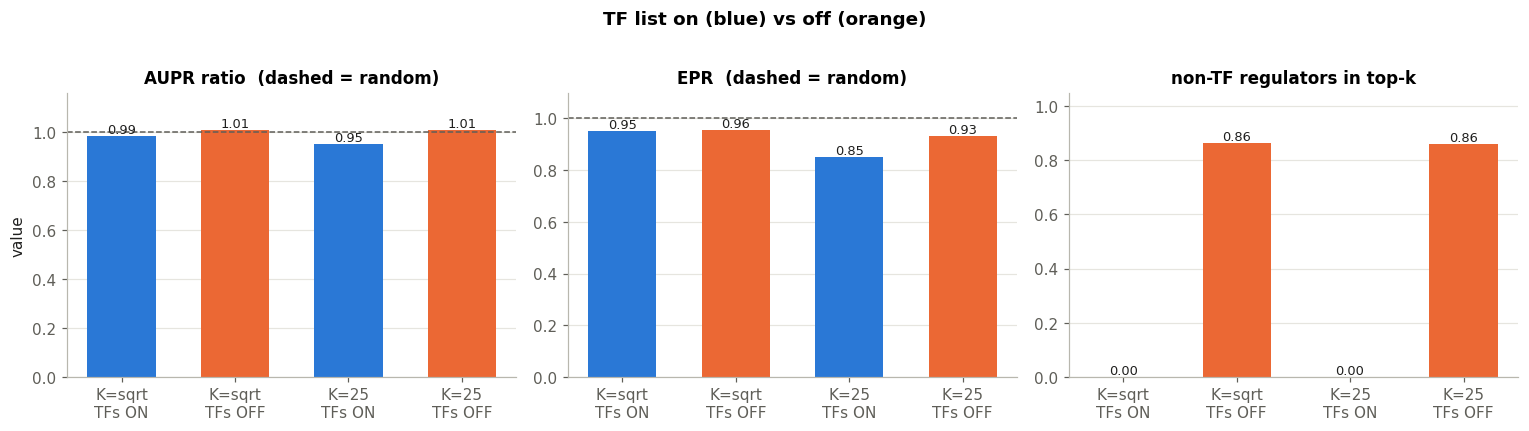

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
labels = [f"K={k}\n{s.replace('TF list ', 'TFs ')}" for k, s in tfcmp.index]
cols = [BLUE if "ON" in s else ORANGE for _, s in tfcmp.index]
for ax, metric, base in zip(axes, ["AUPR ratio", "EPR", "non-TF regulators in top-k"], [1, 1, None]):
    vals = tfcmp[metric].values
    ax.bar(labels, vals, color=cols, width=0.6)
    for x, v in zip(labels, vals):
        ax.text(x, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5, color=INK)
    if base is not None:
        ax.axhline(base, color=INK2, ls="--", lw=1)
    ax.set(title=metric + ("  (dashed = random)" if base is not None else "")); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, max(1.05, vals.max() * 1.15))
axes[0].set_ylabel("value"); axes[2].set_ylim(0, 1.05)
plt.suptitle("TF list on (blue) vs off (orange)", fontweight="bold", y=1.02)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig5_tf_list_on_off.png"), bbox_inches="tight"); plt.show()

## 11. Change 3 — how many cells are needed?

GENIE3 learns one regression per gene from the samples (here: cells). With fewer cells, each forest sees less data. Random subsets of 25% and 50% of the cells (2 repeats each), at K = √ with the TF list, are compared with all cells. This answers the question *"what if you had more (or fewer) samples?"*.

In [21]:
rng = np.random.default_rng(1)
n_cells = EXPR_ALL.shape[0]
cell_rows = [{"fraction": 1.0, "cells": n_cells, "repeat": 0, **accuracy_metrics(MAIN[K_CELLS])}]
for frac in CELL_FRACTIONS:
    for rep in range(CELL_REPEATS):
        idx = np.sort(rng.choice(n_cells, int(round(frac * n_cells)), replace=False))
        V, _ = run_or_load(f"cells{frac}_rep{rep}_K{K_CELLS}", EXPR_ALL[idx], K_CELLS, TF_IDX)
        cell_rows.append({"fraction": frac, "cells": len(idx), "repeat": rep, **accuracy_metrics(V)})
        print(f"{frac:.0%} of cells, repeat {rep}: done")
cells_df = pd.DataFrame(cell_rows)
cell_summary = cells_df.groupby(["fraction", "cells"])[["AUPR ratio", "EPR", "AUROC"]].agg(["mean", "std"])
cell_summary.round(3)

25% of cells, repeat 0: done
25% of cells, repeat 1: done
50% of cells, repeat 0: done
50% of cells, repeat 1: done


AUPR ratio           EPR         AUROC       
                     mean    std   mean    std   mean    std
fraction cells                                              
0.25     105        0.988  0.035  0.990  0.025  0.461  0.011
0.50     210        0.984  0.006  0.977  0.016  0.450  0.004
1.00     421        0.985    NaN  0.951    NaN  0.443    NaN

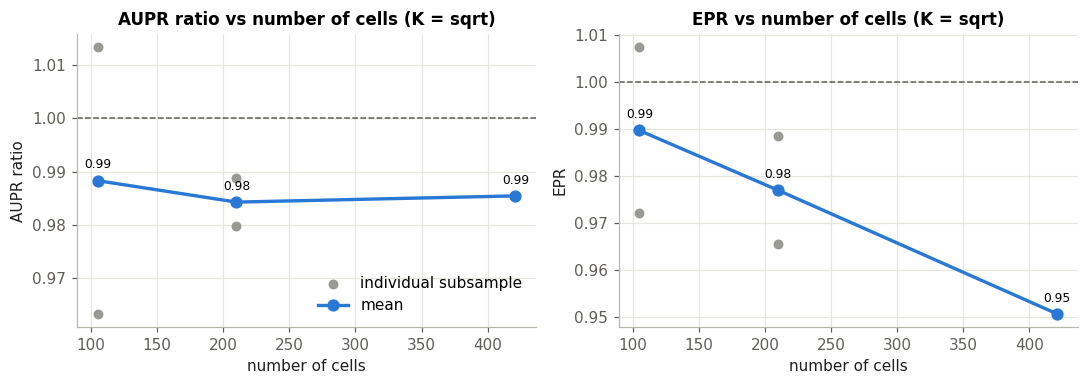

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, metric in zip(axes, ["AUPR ratio", "EPR"]):
    m = cells_df.groupby("cells")[metric].mean()
    ax.scatter(cells_df.cells, cells_df[metric], color=GREY, s=30, zorder=2, label="individual subsample")
    ax.plot(m.index, m.values, color=BLUE, lw=2.2, marker="o", ms=7, zorder=3, label="mean")
    for xi, yi in zip(m.index, m.values):
        ax.annotate(f"{yi:.2f}", (xi, yi), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
    ax.axhline(1, color=INK2, ls="--", lw=1)
    ax.set(title=f"{metric} vs number of cells (K = {K_CELLS})", xlabel="number of cells", ylabel=metric)
axes[0].legend(loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig6_cells.png")); plt.show()

## 12. Change 4 — comparison with a correlation network (course method)

A co-expression network scores each TF–target pair by the absolute Pearson or Spearman correlation of their expression. It is undirected and linear (Pearson) or monotonic (Spearman). Scored on exactly the same evaluable edges.

In [23]:
def corr_vim(expr, method="pearson"):
    df = pd.DataFrame(expr)
    C = df.corr(method=method).fillna(0).values
    V = np.abs(C); np.fill_diagonal(V, 0)
    mask = np.zeros(P, dtype=bool); mask[TF_IDX] = True
    V[~mask, :] = 0                      # same candidate regulators as GENIE3 with the TF list
    return V

best_K = max(K_VALUES, key=lambda K: acc.loc[K_LABEL[K], "AUPR ratio"])
comp = pd.DataFrame([
    {"method": f"GENIE3, K = {K_LABEL[best_K]} (best)", **accuracy_metrics(MAIN[best_K])},
    {"method": f"GENIE3, K = {K_LABEL['sqrt']} (paper default)", **accuracy_metrics(MAIN['sqrt'])},
    {"method": "|Pearson correlation|", **accuracy_metrics(corr_vim(EXPR_ALL, "pearson"))},
    {"method": "|Spearman correlation|", **accuracy_metrics(corr_vim(EXPR_ALL, "spearman"))},
]).set_index("method")
comp.round(3)

,AUPR,AUPR ratio,EPR,AUROC
method,,,,
"GENIE3, K = 1 (best)",0.308,1.024,1.071,0.478
"GENIE3, K = 9 (√) (paper default)",0.296,0.985,0.951,0.443
|Pearson correlation|,0.349,1.162,1.192,0.565
|Spearman correlation|,0.342,1.139,1.185,0.560


## 12b. Does the conclusion depend on the ground truth?

ChIP-seq measures *binding*; STRING collects functional associations (co-expression, literature, experiments). BEELINE evaluates against both. If the mouse STRING network was found in the archive, the same GENIE3 runs and correlation baselines are re-scored against it — no new GENIE3 runs needed. If the ranking of settings is the same under both ground truths, the conclusion is more trustworthy.

STRING: 79 evaluable TFs, 622 true edges, density 0.0158 (max AUPR ratio 63.4)


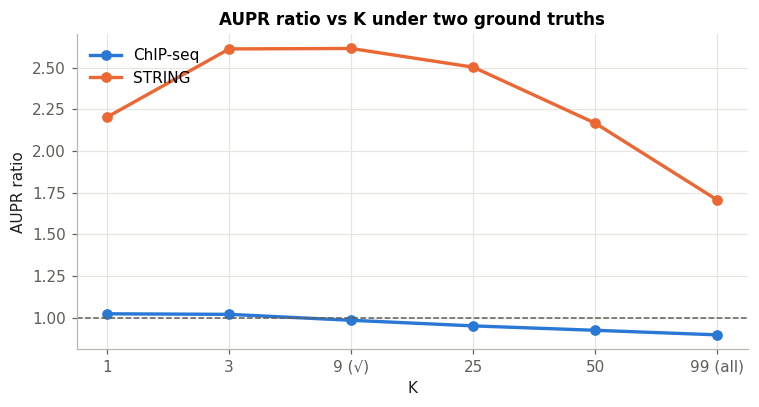

,AUPR ratio (ChIP),EPR (ChIP),AUPR ratio (STRING),EPR (STRING)
setting,,,,
GENIE3 K = 1,1.024,1.071,2.204,4.076
GENIE3 K = 3,1.021,1.040,2.613,5.400
GENIE3 K = 9 (√),0.985,0.951,2.616,5.502
GENIE3 K = 25,0.952,0.852,2.503,5.604
GENIE3 K = 50,0.925,0.781,2.167,5.095
GENIE3 K = 99 (all),0.898,0.719,1.706,4.178
|Pearson correlation|,1.162,1.192,2.346,5.197
|Spearman correlation|,1.139,1.185,1.748,2.853


In [24]:
string_path = os.path.join(DATA_DIR, "STRING-network.csv")
if os.path.exists(string_path):
    STR = make_truth(string_path)
    print(f"STRING: {len(STR['EVAL_REGS'])} evaluable TFs, {STR['N_TRUE']} true edges, "
          f"density {STR['DENSITY']:.4f} (max AUPR ratio {1 / STR['DENSITY']:.1f})")
    rows = [{"setting": f"GENIE3 K = {K_LABEL[K]}", **{f"{m} (ChIP)": v for m, v in accuracy_metrics(MAIN[K]).items()
                                                      if m in ("AUPR ratio", "EPR")},
             **{f"{m} (STRING)": v for m, v in accuracy_metrics(MAIN[K], STR).items() if m in ("AUPR ratio", "EPR")}}
            for K in K_VALUES]
    for method in ["pearson", "spearman"]:
        V = corr_vim(EXPR_ALL, method)
        rows.append({"setting": f"|{method.capitalize()} correlation|",
                     **{f"{m} (ChIP)": v for m, v in accuracy_metrics(V).items() if m in ("AUPR ratio", "EPR")},
                     **{f"{m} (STRING)": v for m, v in accuracy_metrics(V, STR).items() if m in ("AUPR ratio", "EPR")}})
    truth_cmp = pd.DataFrame(rows).set_index("setting")
    truth_cmp.to_csv(os.path.join(RESULTS_DIR, "chip_vs_string.csv"))

    fig, ax = plt.subplots(figsize=(7, 3.8))
    sub = truth_cmp.loc[[f"GENIE3 K = {K_LABEL[K]}" for K in K_VALUES]]
    x = np.arange(len(K_VALUES))
    for col, c, lab in [("AUPR ratio (ChIP)", BLUE, "ChIP-seq"), ("AUPR ratio (STRING)", ORANGE, "STRING")]:
        ax.plot(x, sub[col].values, color=c, lw=2.2, marker="o", ms=6, label=lab)
    ax.axhline(1, color=INK2, ls="--", lw=1)
    ax.set_xticks(x, [K_LABEL[K] for K in K_VALUES])
    ax.set(title="AUPR ratio vs K under two ground truths", xlabel="K", ylabel="AUPR ratio")
    ax.legend(loc="upper left")
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig7_chip_vs_string.png")); plt.show()
    display(truth_cmp.round(3))
else:
    print("STRING-network.csv for mouse was not found in BEELINE-Networks.zip; section skipped.")

## 13. Summary and saved outputs

All tables and figures are saved to `results/`; `requirements.txt` records the package versions. Download `genie3_beeline_results.zip` for the GitHub repository.

In [25]:
summary = acc.join(struct).join(err[["true positive", "reversed", "indirect (A→C→B)", "co-regulated (C→A, C→B)", "other"]])
summary.to_csv(os.path.join(RESULTS_DIR, "summary_K_sweep.csv"))
tfcmp.to_csv(os.path.join(RESULTS_DIR, "tf_list_on_off.csv"))
cells_df.to_csv(os.path.join(RESULTS_DIR, "cell_subsampling.csv"), index=False)
comp.to_csv(os.path.join(RESULTS_DIR, "genie3_vs_correlation.csv"))
pd.DataFrame({"gene": GENES, "is_TF": [g in set(TFS) for g in GENES],
              "evaluable_TF": [k in EVAL_SET for k in range(P)]}).to_csv(os.path.join(RESULTS_DIR, "gene_set.csv"), index=False)

# Top 30 predicted edges (best K), with ground-truth status where known
V = MAIN[best_K]
order_ = np.argsort(-np.where(np.isin(np.arange(P), TF_IDX)[:, None] & ~np.eye(P, dtype=bool), V, -np.inf).ravel())[:30]
top30 = pd.DataFrame([{"regulator": GENES[k // P], "target": GENES[k % P], "score": V.ravel()[k],
                       "ChIP-seq status": ("true" if GOLD.ravel()[k] else "not in ChIP-seq")
                       if (k // P) in EVAL_SET else "unknown (TF not profiled)"} for k in order_])
top30.to_csv(os.path.join(RESULTS_DIR, f"top30_edges_K{best_K}.csv"), index=False)

with open("requirements.txt", "w") as f:
    f.write(f"numpy=={np.__version__}\npandas=={pd.__version__}\nscikit-learn=={sklearn.__version__}\n"
            f"scipy=={scipy.__version__}\nmatplotlib=={matplotlib.__version__}\n")
shutil.copy("download_data.py", RESULTS_DIR); shutil.copy("requirements.txt", RESULTS_DIR)
shutil.make_archive("genie3_beeline_results", "zip", RESULTS_DIR)
print("Saved to", RESULTS_DIR, "and genie3_beeline_results.zip")
summary.round(3).T

Saved to /content/genie3_beeline_mESC/results and genie3_beeline_results.zip


K,1,3,9 (√),25,50,99 (all)
K_eff,1.000,3.000,9.000,25.000,50.000,99.000
AUPR,0.308,0.307,0.296,0.286,0.278,0.270
AUPR ratio,1.024,1.021,0.985,0.952,0.925,0.898
EPR,1.071,1.040,0.951,0.852,0.781,0.719
AUROC,0.478,0.470,0.443,0.430,0.424,0.418
seconds,308.532,383.137,697.020,1370.010,2436.138,4576.876
effective regulators / target,89.455,70.591,45.725,30.387,22.434,17.253
direction accuracy (TF→TF),0.401,0.477,0.500,0.483,0.459,0.453
hub recovery (Spearman),-0.031,-0.085,-0.061,-0.061,0.073,0.173
true positive,0.322,0.312,0.285,0.256,0.235,0.216


In [26]:
top30

,regulator,target,score,ChIP-seq status
0,HIST1H1B,HIST1H1D,0.049499,unknown (TF not profiled)
1,HIST1H1D,HIST1H2BK,0.046927,unknown (TF not profiled)
2,HIST1H1D,HIST1H1A,0.046734,unknown (TF not profiled)
3,HIST1H1B,HIST1H2BF,0.046095,unknown (TF not profiled)
4,HIST1H1D,HIST1H2BL,0.045359,unknown (TF not profiled)
5,HIST1H1B,HIST1H2BN,0.044020,unknown (TF not profiled)
6,HIST1H1D,HIST1H3H,0.042030,unknown (TF not profiled)
7,HIST1H1B,HIST1H2AI,0.041838,unknown (TF not profiled)
8,HIST1H1D,HIST1H2BN,0.041496,unknown (TF not profiled)
9,KPNA2,GM10184,0.041383,unknown (TF not profiled)


In [2]:
!ls /content/genie3_beeline_mESC/cache/*/ | head

ls: cannot access '/content/genie3_beeline_mESC/cache/*/': No such file or directory


In [27]:
if IN_COLAB:
    from google.colab import files
    files.download("genie3_beeline_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## 14. Results and Interpretation

### 14.1 Expected outcome

Based on the original GENIE3 paper and my DREAM4 results, I expected larger K values to improve network inference, as the model would have more candidate regulators to choose from at each split. I also expected the known TF list to improve predictions by excluding unlikely regulators, and more cells to provide better estimates of gene expression relationships.

However, I expected the real mESC data to be more challenging than DREAM4 because of expression noise, dropout and differences in cell state during differentiation.

### 14.2 Accuracy across K values

The results were different from DREAM4. Against the ChIP-seq reference, the AUPR ratio decreased from 1.024 at K=1 to 0.898 at K=99. Since a ratio of 1 represents random-ranking performance, none of the K settings showed a meaningful improvement over random.

AUROC also decreased from 0.478 to 0.418. This suggests that allowing more candidate regulators at each split did not help recover ChIP-seq interactions.

Unlike DREAM4, where larger K performed better, the smallest K gave the highest ChIP-seq score. However, the differences between settings were small compared with the overall lack of predictive performance. I would therefore not consider K=1 a reliably better setting without further testing.

### 14.3 Network structure

Increasing K reduced the effective number of regulators per target from approximately 89 to 17. With small K, importance was distributed across many predictors, while larger K concentrated importance among fewer genes.

However, this increased selectivity did not improve accuracy. Direction accuracy remained around 0.40–0.50, close to or below random expectation. Hub recovery was also weak, suggesting that GENIE3 did not consistently identify the most connected regulators in the ChIP-seq network.

The edge-overlap results showed that changing K also changed which interactions appeared among the top predictions.

### 14.4 Error analysis

Indirect relationships formed a large proportion of the incorrect predictions, decreasing from approximately 42% at K=1 to 27% at K=99.

This may happen because genes connected through an intermediate regulator can have similar expression patterns, even without a direct interaction.

The "other" category includes edges that could not be explained using the available reference network. These may be incorrect predictions, but they could also represent interactions missing from the ChIP-seq reference.

Since the reference network is relatively dense, indirect paths are common. Therefore, these categories should be treated as possible explanations rather than confirmed error mechanisms.

### 14.5 Effect of prior TF knowledge

I expected restricting regulators to known TFs to improve performance, as the original paper showed that TF information was useful for E. coli.

However, the TF list did not improve ChIP-seq AUPR in my experiment. At K=sqrt, the AUPR ratio was 0.985 with the TF list and 1.011 without it.

The main difference was in network composition. Without the TF list, approximately 86% of the strongest predicted edges came from genes not included in the known TF set.

This suggests that TF knowledge is useful for restricting predictions to biologically plausible transcriptional regulators, even if it does not improve their ranking against this reference network.

### 14.6 Effect of cell number

Reducing the dataset to 25% or 50% of the cells did not consistently reduce performance. The results remained close to those obtained using all 421 cells.

This suggests that simply increasing sample size may not resolve the poor ChIP-seq recovery. With ten times more cells, I would expect more reliable expression relationships, but only if the additional cells capture relevant biological variation.

If the main limitation is that mRNA expression does not reflect TF activity, collecting more cells alone may not substantially improve the inferred network.

### 14.7 Comparison with correlation

Pearson and Spearman correlation performed slightly better than GENIE3 against the ChIP-seq reference, with AUPR ratios of 1.162 and 1.139 respectively.

This was interesting because GENIE3 can model nonlinear relationships and assign different scores to opposite directions, whereas correlation only measures association.

However, these additional capabilities did not improve ChIP-seq recovery in this dataset. The correlation results were also only modestly above random, so neither method demonstrated strong regulatory-network reconstruction.

### 14.8 Assumptions and reliability

One important limitation is that GENIE3 assumes expression measurements provide useful information about regulatory activity. In this dataset, TF mRNA levels may not reflect actual TF protein activity or DNA binding.

The cells also represent different stages of differentiation rather than identical steady-state conditions. Dropout and cell-state differences can introduce expression patterns that may not correspond to direct regulation.

To assess the reliability of the predictions, I compared them with ChIP-seq and STRING reference networks. The results differed substantially: GENIE3 was close to random against ChIP-seq but reached an AUPR ratio of approximately 2.6 against STRING at K=9.

This suggests that performance depends strongly on what the reference network measures. STRING represents broader functional associations, whereas ChIP-seq provides evidence of TF binding.

Before trusting the strongest predicted interactions, I would check whether the regulators are known TFs, whether the edges have independent experimental support, and whether the relationships could be explained by co-expression or common cell-state effects.

Overall, these results show that increasing model complexity does not necessarily improve biological accuracy. GENIE3 can identify predictive relationships, but these should be treated as regulatory hypotheses rather than confirmed interactions.


## 15. Limitations of this analysis

* **Reduced gene set** (100 TFs + 400 genes instead of BEELINE's 620 TFs + 500) for runtime; results may differ in the full setting.
* **Ground truth = ChIP-seq binding**, which is neither complete nor proof of regulation; only TFs with ChIP data can be scored (see Section 4).
* **One dataset, one ground truth.** BEELINE also provides STRING and non-specific ChIP-seq networks, and other cell types; conclusions are specific to mESC.
* **K values not run with the TF list off** (K = 3, 50, all) because of runtime.
* **300 trees** instead of 1000 (Section 6 checks the effect).
* **Choosing the "best" K using the ground truth is optimistic**; in practice no ground truth exists.

## References

1. Huynh-Thu VA, Irrthum A, Wehenkel L, Geurts P (2010). Inferring regulatory networks from expression data using tree-based methods. *PLoS ONE* 5(9): e12776.
2. Pratapa A, Jalihal AP, Law JN, Bharadwaj A, Murali TM (2020). Benchmarking algorithms for gene regulatory network inference from single-cell transcriptomic data. *Nature Methods* 17: 147–154. Data: doi:10.5281/zenodo.3701939 (CC BY-NC 4.0).
3. Hayashi T, et al. (2018). Single-cell full-length total RNA sequencing uncovers dynamics of recursive splicing and enhancer RNAs. *Nature Communications* 9: 619. (mESC data, GEO GSE98664.)
4. Original GENIE3 code: https://github.com/vahuynh/GENIE3 · BEELINE: https://github.com/Murali-group/Beeline
5. Pedregosa F, et al. (2011). Scikit-learn: Machine learning in Python. *JMLR* 12: 2825–2830.

**AI-use disclosure:**
Claude was used primarily to assist with Python code development, debugging, troubleshooting, and implementing GENIE3 for the DREAM4 and BEELINE mESC datasets. AI assistance was also used for technical clarification and reviewing written explanations.